# E91 Quantum Cryptography: Catching an Eavesdropper with Entanglement

E91 (Ekert, 1991) is a quantum cryptography protocol for sharing a secret encryption key. Alice and Bob use entangled qubit pairs to build the key, then use a Bell test to check that nobody intercepted it.

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()
rng = np.random.default_rng()

### The circuit

Each round creates an entangled pair. Alice and Bob each measure their qubit at an angle chosen at random from their own list, and the closer the angles they picked, the more their results agree, and if they choose the same angle they will get the same result. like the polarized lenses analogy.

If Eve is listening, she measures Bob's qubit at her own angle first and sends him a copy of what she saw.

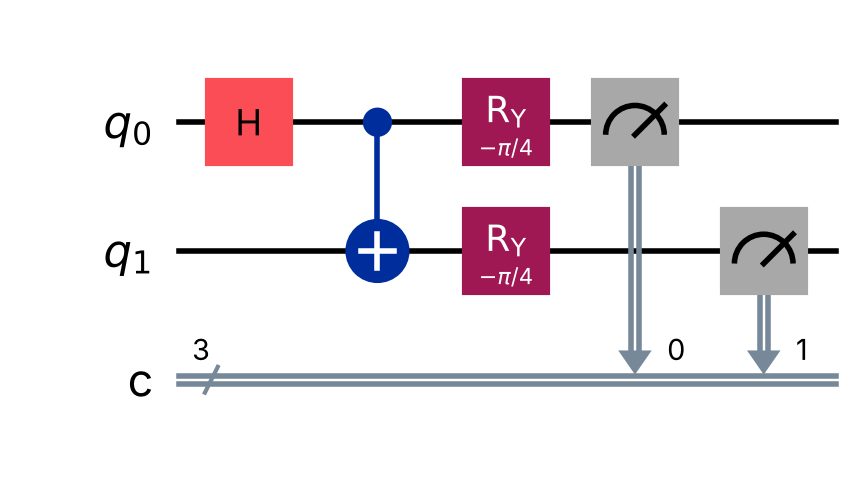

In [3]:
alice_angles = [0, np.pi / 4, np.pi / 2]
bob_angles   = [np.pi / 4, np.pi / 2, 3 * np.pi / 4]

def make_pair(alice_angle, bob_angle, eve_angle=None):
    qc = QuantumCircuit(2, 3)
    qc.h(0)
    qc.cx(0, 1)

    if eve_angle is not None:
        qc.ry(-eve_angle, 1)
        qc.measure(1, 2)
        qc.ry(eve_angle, 1)

    qc.ry(-alice_angle, 0)
    qc.ry(-bob_angle, 1)
    qc.measure(0, 0)
    qc.measure(1, 1)
    return qc

make_pair(alice_angles[1], bob_angles[0]).draw("mpl")

### Running the rounds
Rounds with the same angle choices are run together to keep it fast.

In [4]:
def run_rounds(n_rounds, eve=False):
    alice_pick = rng.integers(0, 3, n_rounds)
    bob_pick = rng.integers(0, 3, n_rounds)
    eve_pick = rng.integers(0, 3, n_rounds) if eve else np.full(n_rounds, -1)

    alice_bits = np.zeros(n_rounds, dtype=int)
    bob_bits = np.zeros(n_rounds, dtype=int)

    for a, b, e in set(zip(alice_pick, bob_pick, eve_pick)):
        these = (alice_pick == a) & (bob_pick == b) & (eve_pick == e)
        eve_angle = bob_angles[e] if e >= 0 else None
        qc = transpile(make_pair(alice_angles[a], bob_angles[b], eve_angle), sim)
        memory = sim.run(qc, shots=int(these.sum()), memory=True).result().get_memory()
        alice_bits[these] = [int(m[-1]) for m in memory]
        bob_bits[these] = [int(m[-2]) for m in memory]

    return alice_pick, bob_pick, alice_bits, bob_bits

rounds = 10000
safe = run_rounds(rounds)

### The key
Alice and Bob publicly compare which angles they used, but never their results, and rounds where they picked the same angle become the key.

In [5]:
def make_key(alice_pick, bob_pick, alice_bits, bob_bits):
    same_angle = ((alice_pick == 1) & (bob_pick == 0)) | ((alice_pick == 2) & (bob_pick == 1))
    return alice_bits[same_angle], bob_bits[same_angle]

def show_key(alice_key, bob_key, n=40):
    a = "".join(map(str, alice_key[:n]))
    b = "".join(map(str, bob_key[:n]))
    marks = "".join(" " if x == y else "^" for x, y in zip(a, b))
    errors = np.mean(alice_key != bob_key)
    print(f"alice's key: {a}")
    print(f"bob's key:   {b}")
    print(f"mismatches:  {marks}")
    print(f"key length: {len(alice_key)} bits, error rate: {errors:.1%}")
    return errors

safe_error = show_key(*make_key(*safe))

alice's key: 0010010000011110100101101100111000110001
bob's key:   0010010000011110100101101100111000110001
mismatches:                                          
key length: 2224 bits, error rate: 0.0%


### The Bell test
The remaining rounds are used to compute S, a measure of how correlated their results are. Anything that's not entangled can reach at most 2. Perfect entanglement gives about 2.83. If S is above 2, nobody measured the pairs on the way.

In [6]:
def correlation(alice_pick, bob_pick, alice_bits, bob_bits, a, b):
    these = (alice_pick == a) & (bob_pick == b)
    signs = (1 - 2 * alice_bits[these]) * (1 - 2 * bob_bits[these])
    return signs.mean()

def bell_score(results):
    E = lambda a, b: correlation(*results, a, b)
    return E(0, 0) - E(0, 2) + E(2, 0) + E(2, 2)

safe_S = bell_score(safe)
print(f"S = {safe_S:.2f}")

S = 2.84


S varies a little around 2.83 between runs, since it's estimated from a limited number of rounds.

### Why 2 is the limit
Suppose each pair carried pre-decided answers instead of being entangled, written as +1 or −1: a1 and a2 for Alice's angles, b1 and b2 for Bob's. For one pair:

S = a1·b1 − a1·b2 + a2·b1 + a2·b2 = a1·(b1 − b2) + a2·(b1 + b2)

If b1 = b2, the first bracket is 0 and the second is ±2. If b1 ≠ b2, it's the other way around. Either way every pair gives exactly ±2, so the average can't exceed 2. This is the CHSH inequality.

Entangled pairs beat it, so their results weren't pre-decided. Measuring a qubit turns it into exactly this kind of pre-decided state, which is how Eve gets caught.

### Adding Eve
Eve intercepts Bob's qubit every round, measures it at a random angle, and sends him a copy. She can't copy the qubit without measuring it.

In [7]:
spied = run_rounds(rounds, eve=True)

spied_error = show_key(*make_key(*spied))
spied_S = bell_score(spied)
print(f"S = {spied_S:.2f}")

alice's key: 0110111011110100010011010100111011101001
bob's key:   0011011011110100011000000100101111101011
mismatches:   ^ ^^             ^ ^^ ^     ^ ^      ^ 
key length: 2201 bits, error rate: 22.6%
S = 1.30


Measuring broke the entanglement. The keys no longer match, and S dropped to 2 or below. Alice and Bob discard the key.

### Comparison

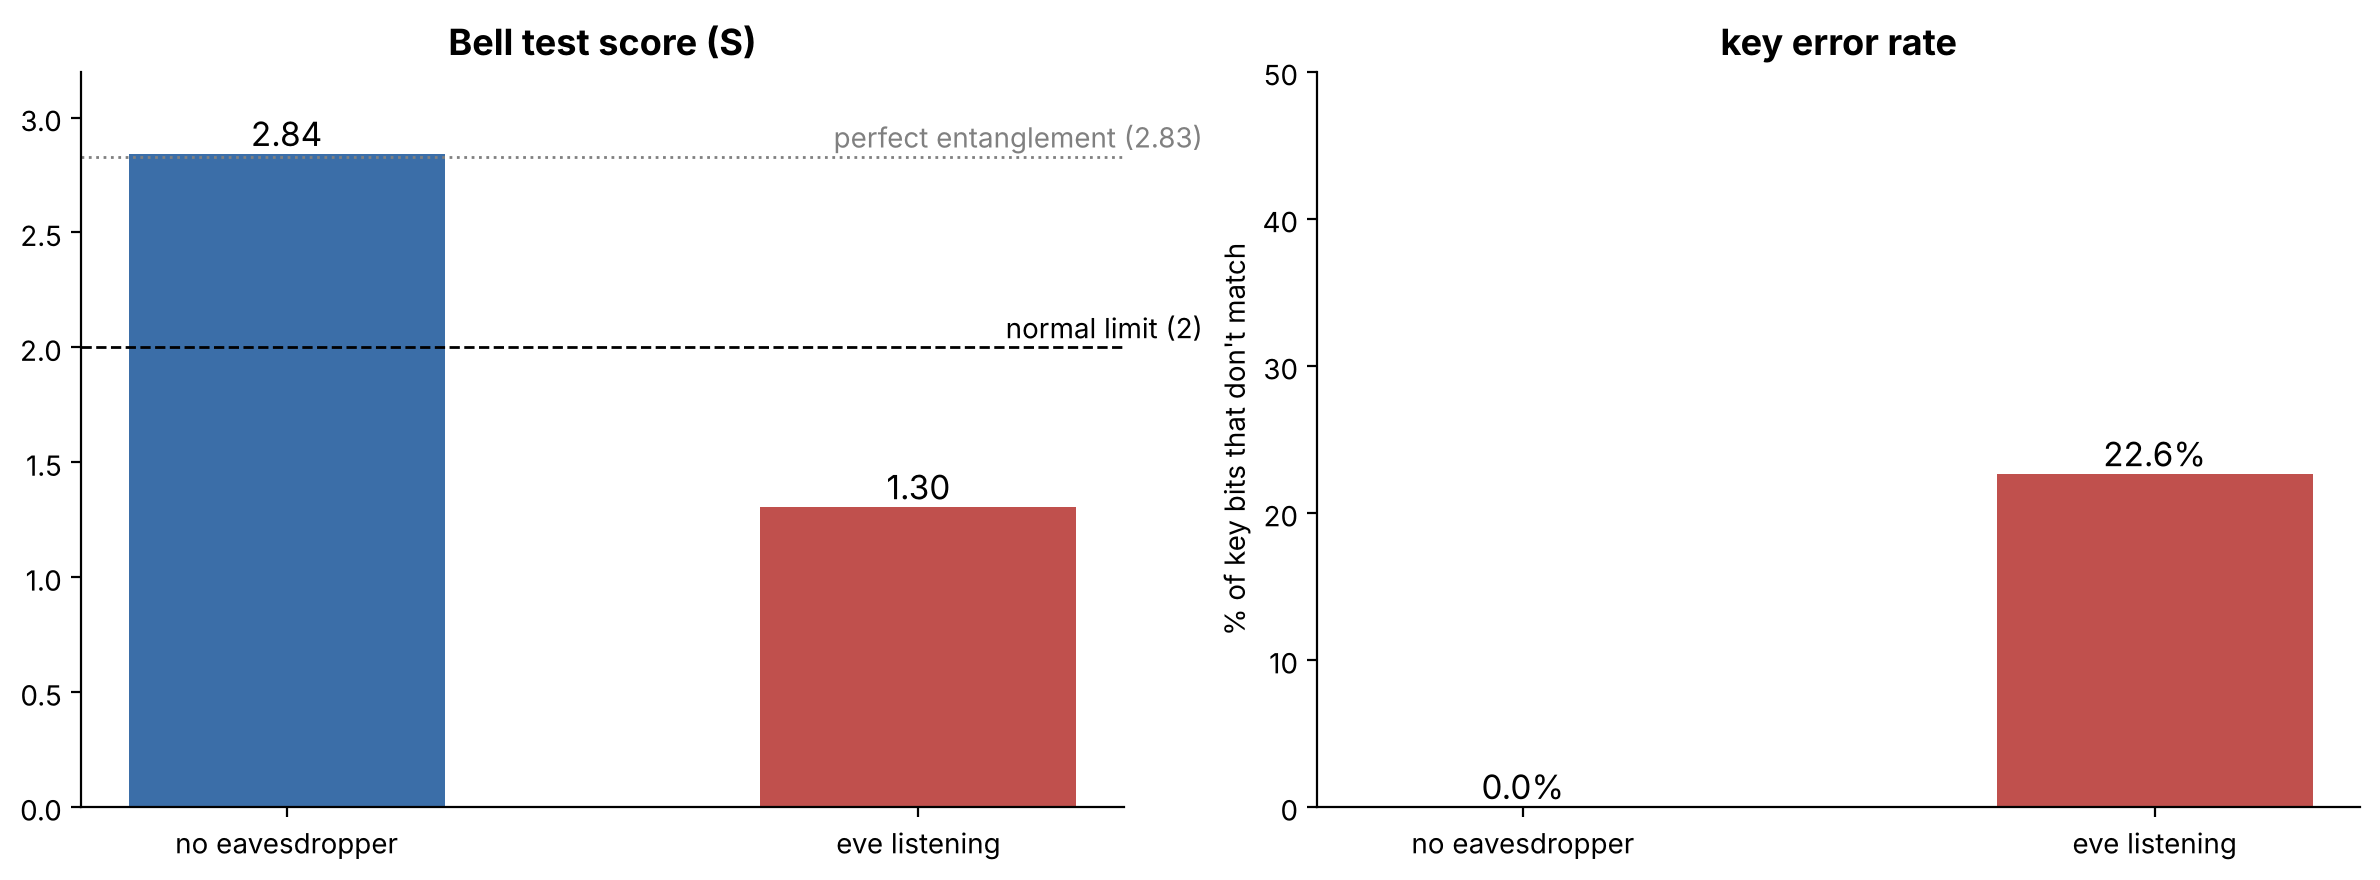

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
labels = ["no eavesdropper", "eve listening"]
colors = ["#3b6ea8", "#c0504d"]

bars = left.bar(labels, [safe_S, spied_S], color=colors, width=0.5)
left.bar_label(bars, fmt="%.2f", fontsize=12)
left.axhline(2, color="black", linestyle="--", linewidth=1)
left.text(1.45, 2.04, "normal limit (2)", ha="right", fontsize=10)
left.axhline(2 * np.sqrt(2), color="gray", linestyle=":", linewidth=1)
left.text(1.45, 2.87, "perfect entanglement (2.83)", ha="right", fontsize=10, color="gray")
left.set_ylim(0, 3.2)
left.set_title("Bell test score (S)", fontsize=13, fontweight="bold")

bars = right.bar(labels, [safe_error * 100, spied_error * 100], color=colors, width=0.5)
right.bar_label(bars, fmt="%.1f%%", fontsize=12)
right.set_ylim(0, 50)
right.set_title("key error rate", fontsize=13, fontweight="bold")
right.set_ylabel("% of key bits that don't match")

for ax in (left, right):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Notes
- E91 secures how the key is shared. Messages are then encrypted normally with that key.
- Real systems use entangled photons over noisy channels, so they tolerate some error.
- This is a simplified simulation for learning.